# 01_intuition.ipynb – JEPA Intuition: Why Non-Generative World Models + LeJEPA Theory

**Last updated:** February 2026  
**Focus:** Build strong conceptual understanding before coding. Compare JEPA to generative approaches and introduce the latest theoretical foundation (LeJEPA, Nov 2025).



## 1. What is a "World Model" and why do we care?

A world model is an internal representation that lets an agent predict what happens if it takes certain actions — without needing the real world every time.

Two main philosophies in 2025–2026:

- **Generative / Autoregressive** (e.g., Sora-style video diffusion, GPT-like next-token, many game-world models)  
  → Predict raw pixels / tokens step-by-step → great for creative sampling, but compute-heavy, compounding errors, mode-covering issues.

- **Non-generative / JEPA-style** (Yann LeCun's path)  
  → Predict abstract **latent representations** instead of raw data  
  → Energy-based / predictive in embedding space → more efficient, avoids pixel-level hallucination, better for planning & reasoning

**Quick poll question (add cell for learners to think):**  
Which would you rather use for robot control: predicting every pixel perfectly, or predicting useful abstract features + distances in latent space?

## 2. Visual Comparison: Reconstruction vs Prediction Paradigms

TODO: Insert diagrams here (hand-drawn sketches or matplotlib-generated)

Cell ideas:

- Left: Autoencoder / VAE → input → encode → decode → reconstruct pixels  
- Middle: Diffusion / GAN → noise → denoise / generate full image  
- Right: JEPA → two views/context → encode → predict **one latent from the other** (no decoder needed!)

**Key advantage of JEPA:** No need to model low-level details (texture, lighting) → focus on semantics, dynamics, affordances.

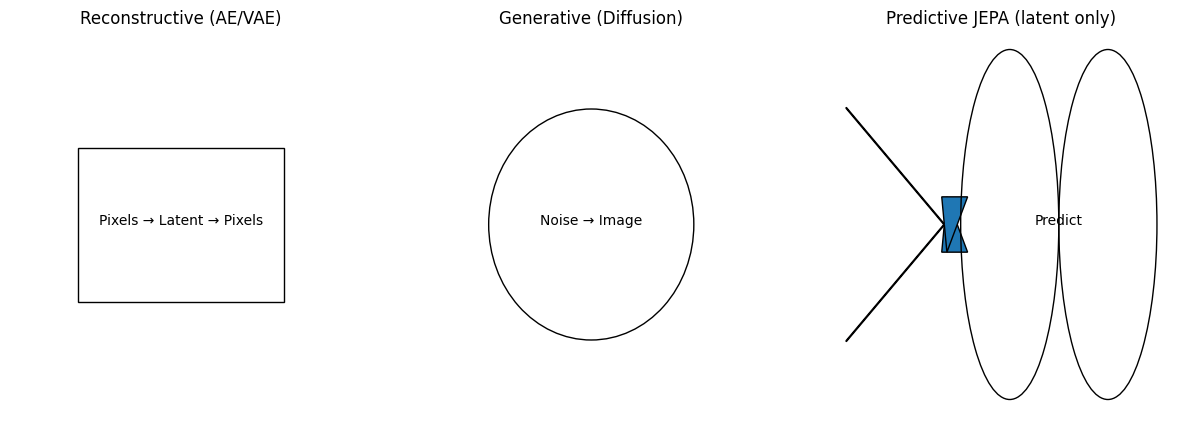

In [10]:
# TODO: Simple schematic plot – run this cell
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle, Rectangle

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# AE/VAE
ax[0].add_patch(Rectangle((0.2, 0.3), 0.6, 0.4, fill=False))
ax[0].text(0.5, 0.5, "Pixels → Latent → Pixels", ha='center')
ax[0].set_title("Reconstructive (AE/VAE)")

# Diffusion
ax[1].add_patch(Circle((0.5, 0.5), 0.3, fill=False))
ax[1].text(0.5, 0.5, "Noise → Image", ha='center')
ax[1].set_title("Generative (Diffusion)")

# JEPA
ax[2].arrow(0.1, 0.6, 0.3, -0.1, head_width=0.05)
ax[2].arrow(0.1, 0.4, 0.3, 0.1, head_width=0.05)
ax[2].add_patch(Circle((0.6, 0.5), 0.15, fill=False, label="z_context"))
ax[2].add_patch(Circle((0.9, 0.5), 0.15, fill=False, label="z_target"))
ax[2].text(0.75, 0.5, "Predict", ha='center')
ax[2].set_title("Predictive JEPA (latent only)")

for a in ax:
    a.axis('off')
plt.show()

## 3. The Collapse Problem – Why Many SSL Methods Fail

Common failure modes in self-supervised learning:

- **Dimensional collapse** — all embeddings become constant / low-rank
- **Trivial solutions** — constant predictors, collapsed representations

Generative models fight this with reconstruction loss + heavy regularization.
Contrastive methods (SimCLR) fight via negatives.
Early JEPA (I-JEPA) used VICReg / Barlow Twins-style decorrelation.

**Latest solution:** LeJEPA (Balestriero & LeCun, Nov 2025, arXiv 2511.08544)
→ Theory proves the optimal embedding distribution is isotropic Gaussian (spherical, equal variance in all directions) → minimizes worst-case downstream prediction risk.
→ Introduces SIGReg (Sketched Isotropic Gaussian Regularization) — efficient, linear-complexity regularizer that gently pushes embeddings toward this ideal shape.
→ Result: No stop-gradient, no teacher-student, no schedulers, no many hyperparameters — just predictive loss + λ × SIGReg.

TODO: Visualize isotropic Gaussian vs collapsed / anisotropic

Explain: SIGReg uses sketched (random projections) matching to high-dim Gaussian → avoids curse of dimensionality.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


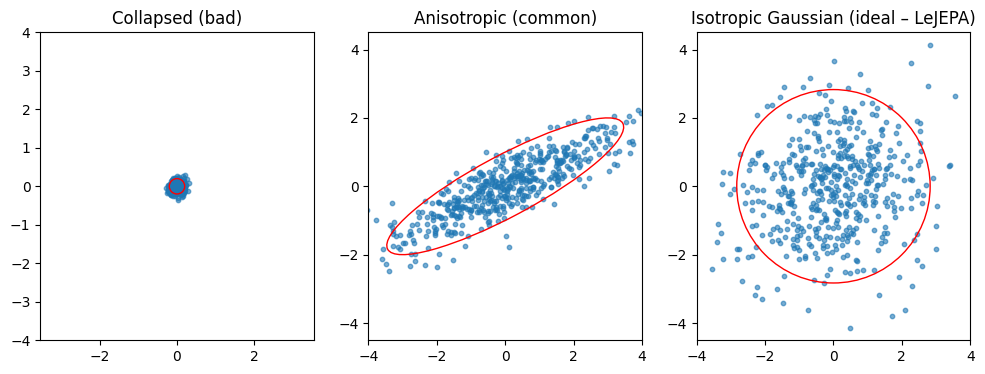

In [ ]:
# TODO: 2D embedding scatter + covariance ellipse
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

def plot_embeddings(title, cov):
    rng = np.random.default_rng(42)
    z = rng.multivariate_normal([0,0], cov, 500)
    plt.scatter(z[:,0], z[:,1], s=10, alpha=0.6)
    # Ellipse from covariance
    lambda_, v = np.linalg.eig(cov)
    lambda_ = np.sqrt(lambda_)
    ell = Ellipse(xy=(0,0), width=lambda_[0]*2*2, height=lambda_[1]*2*2,
                  angle=np.rad2deg(np.arccos(v[0,0])), color='red', fill=False)
    plt.gca().add_artist(ell)
    plt.title(title)
    plt.axis('equal'); plt.xlim(-4,4); plt.ylim(-4,4)

plt.figure(figsize=(12,4))
plt.subplot(131); plot_embeddings("Collapsed (bad)", np.array([[0.01,0],[0,0.01]]))
plt.subplot(132); plot_embeddings("Anisotropic (common)", np.array([[3,1.5],[1.5,1]]))
plt.subplot(133); plot_embeddings("Isotropic Gaussian (ideal – LeJEPA)", np.eye(2)*2)
plt.show()

## 4. Toy 2D Interactive Example (Core Hands-On Part)

TODO: Implement a minimal 2D JEPA demo to show collapse vs non-collapse.

Plan:

- Generate 2D Swiss-roll / circle data
- Define simple MLP encoders
- Train 3 variants:
  1. Naive predictive (→ collapse)
  2. With variance/covariance regularization (like VICReg)
  3. With "ideal" isotropic loss (proxy for SIGReg)


In [1]:
# ────────────────────────────────────────────────────────────────
# Toy 2D JEPA Demonstration – Collapse vs Regularized Variants
# ────────────────────────────────────────────────────────────────
# Goal: Show how naive prediction collapses → how regularization helps
#       (inspired by JEPA collapse discussions + LeJEPA isotropic ideal)

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll

In [2]:
# ── Hyperparameters ────────────────────────────────────────────────
n_samples = 2000
latent_dim = 2          # keep low for nice 2D viz
n_epochs = 1500
batch_size = 256
lr = 0.005
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
# ── Generate toy data: Swiss roll + simple "future" view ───────────
# We simulate two correlated 2D views (like context & target)
X, _ = make_swiss_roll(n_samples=n_samples, noise=0.8, random_state=42)
X = X[:, [0, 2]]  # project to 2D

# Create "context" and "target" views: target = context + small dynamics + noise
rng = np.random.default_rng(42)
context = X.astype(np.float32)
target = (context + np.column_stack([
    0.4 * np.sin(context[:,0] * 0.1) + rng.normal(0, 0.4, n_samples),
    0.6 * np.cos(context[:,1] * 0.08) + rng.normal(0, 0.4, n_samples)
])).astype(np.float32)  # ← Ensure float32 type!

# Normalize roughly to unit scale
context = (context - context.mean(0)) / (context.std(0) + 1e-6)
target  = (target  - target.mean(0))  / (target.std(0)  + 1e-6)

# To torch
context_t = torch.from_numpy(context).to(device)
target_t  = torch.from_numpy(target).to(device)


In [4]:
# ── Simple MLP Encoder & Predictor ─────────────────────────────────
class Encoder(nn.Module):
    def __init__(self, in_dim=2, hid=64, out_dim=latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hid), nn.ReLU(),
            nn.Linear(hid, hid),    nn.ReLU(),
            nn.Linear(hid, out_dim)
        )
    def forward(self, x):
        return self.net(x)

class Predictor(nn.Module):
    def __init__(self, in_dim=latent_dim, hid=32, out_dim=latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hid), nn.ReLU(),
            nn.Linear(hid, out_dim)
        )
    def forward(self, z):
        return self.net(z)

In [5]:
# ── Losses ─────────────────────────────────────────────────────────
def mse_loss(pred, targ):
    return ((pred - targ) ** 2).mean()

def variance_reg(z, eps=1e-4):
    """Encourage features to have unit variance (per VICReg-inspired)"""
    var = z.var(dim=0) + eps
    return torch.mean(torch.relu(1 - var))   # push var → 1

def covariance_reg(z):
    """Minimize off-diagonal covariance (decorrelation)"""
    z = z - z.mean(0, keepdim=True)
    cov = (z.T @ z) / (z.shape[0] - 1)
    off_diag = cov - torch.eye(cov.shape[0], device=cov.device)
    return (off_diag ** 2).mean()

def isotropic_proxy(z, target_std=1.5):
    """Very simple proxy toward isotropic Gaussian:
       - center → 0
       - trace(var) ≈ target_std² × dim
       - encourage low anisotropy (via cov off-diag penalty)"""
    mean = z.mean(0)
    centered = z - mean
    cov = (centered.T @ centered) / (z.shape[0] - 1)
    trace = cov.trace()
    off_diag_penalty = (cov - torch.diag(cov.diag())).pow(2).mean()
    return (mean.abs().mean() +
            (trace - target_std**2 * latent_dim).abs() * 0.1 +
            off_diag_penalty * 5.0)

In [6]:
# ── Training function ──────────────────────────────────────────────
def train_variant(name, reg_weight=0.0, use_isotropic=False, color='C0'):
    enc = Encoder().to(device)
    pred = Predictor().to(device)
    opt = optim.Adam(list(enc.parameters()) + list(pred.parameters()), lr=lr)

    losses = []
    embeddings = []

    for epoch in range(n_epochs):
        idx = torch.randperm(n_samples, device=device)[:batch_size]
        c = context_t[idx]
        t = target_t[idx]

        z_c = enc(c)
        z_hat = pred(z_c)
        z_t = enc(t).detach()           # stop-grad on target (classic JEPA)

        recon_loss = mse_loss(z_hat, z_t)

        reg_loss = 0.0
        if reg_weight > 0:
            z_all = enc(torch.cat([c, t]))   # reg on both views
            reg_loss += variance_reg(z_all) * reg_weight
            reg_loss += covariance_reg(z_all) * reg_weight

        if use_isotropic:
            reg_loss += isotropic_proxy(enc(context_t)) * 0.5   # global reg

        loss = recon_loss + reg_loss
        opt.zero_grad()
        loss.backward()
        opt.step()

        losses.append(loss.item())

        if epoch % 300 == 0 or epoch == n_epochs-1:
            with torch.no_grad():
                emb = enc(context_t).cpu().numpy()
                embeddings.append(emb)
            print(f"[{name}] epoch {epoch:4d} | loss {loss:.4f}")

    # Final embedding
    with torch.no_grad():
        final_emb = enc(context_t).cpu().numpy()

    # Plot loss curve
    plt.plot(losses, label=name, color=color, alpha=0.7)

    return final_emb, losses[-1]

[Naive JEPA] epoch    0 | loss 0.1299
[Naive JEPA] epoch  300 | loss 0.1540
[Naive JEPA] epoch  600 | loss 0.0915
[Naive JEPA] epoch  900 | loss 0.0733
[Naive JEPA] epoch 1200 | loss 0.0996
[Naive JEPA] epoch 1499 | loss 0.0921
[VICReg-style] epoch    0 | loss 1.5592
[VICReg-style] epoch  300 | loss 0.0204
[VICReg-style] epoch  600 | loss 0.0518
[VICReg-style] epoch  900 | loss 0.0183
[VICReg-style] epoch 1200 | loss 0.0193
[VICReg-style] epoch 1499 | loss 0.0499
[Isotropic-proxy (LeJEPA-like)] epoch    0 | loss 0.3997
[Isotropic-proxy (LeJEPA-like)] epoch  300 | loss 0.0305
[Isotropic-proxy (LeJEPA-like)] epoch  600 | loss 0.0112
[Isotropic-proxy (LeJEPA-like)] epoch  900 | loss 0.0184
[Isotropic-proxy (LeJEPA-like)] epoch 1200 | loss 0.0152
[Isotropic-proxy (LeJEPA-like)] epoch 1499 | loss 0.0236


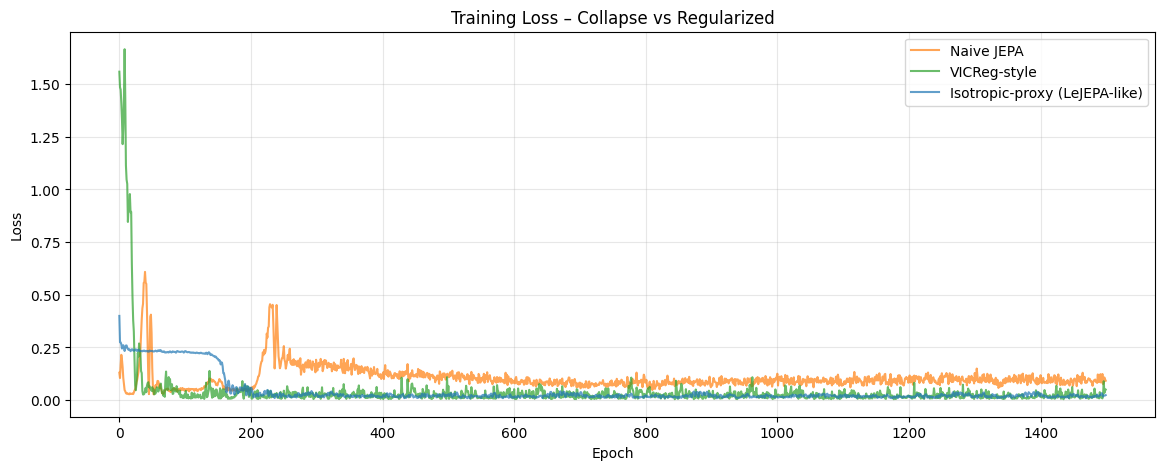

In [7]:
# ── Run the three variants ─────────────────────────────────────────
plt.figure(figsize=(14, 5))

# Variant 1: Naive → expect collapse
emb_naive, loss_naive = train_variant("Naive JEPA", reg_weight=0.0, color='C1')

# Variant 2: Variance + Covariance reg (VICReg-like)
emb_vicreg, loss_vicreg = train_variant("VICReg-style", reg_weight=1.0, color='C2')

# Variant 3: Stronger isotropic proxy (LeJEPA-inspired direction)
emb_iso, loss_iso = train_variant("Isotropic-proxy (LeJEPA-like)", use_isotropic=True, color='C0')

plt.title("Training Loss – Collapse vs Regularized")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(); plt.grid(alpha=0.3); plt.show()

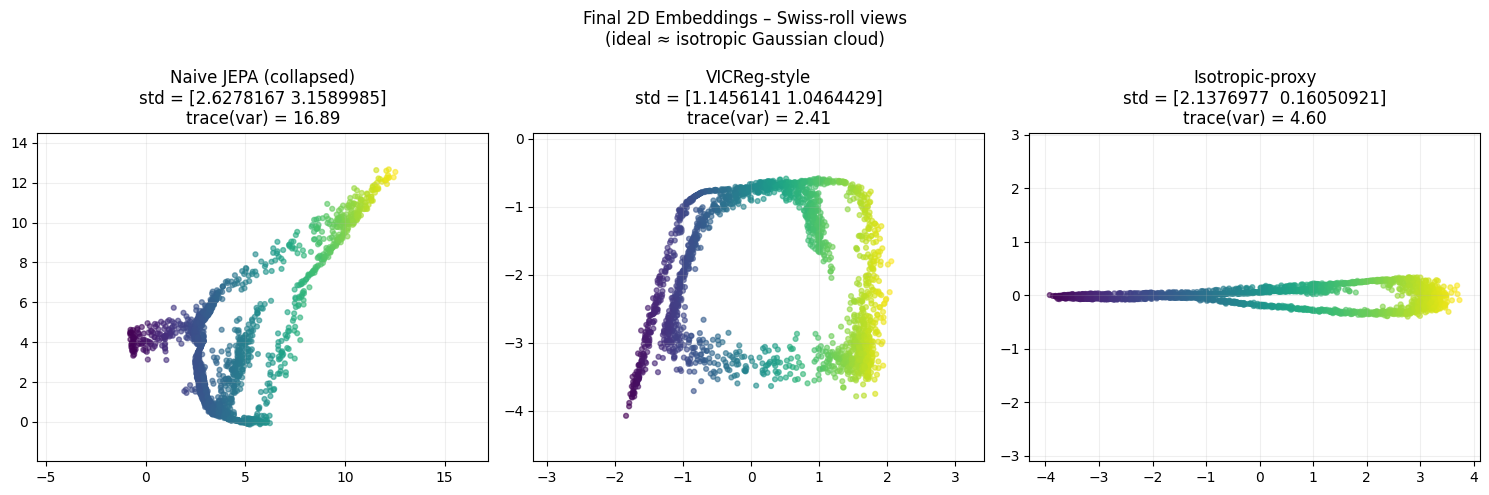

In [8]:
# ── Visualize final embeddings ─────────────────────────────────────
def plot_embedding(emb, title, ax):
    ax.scatter(emb[:,0], emb[:,1], s=12, alpha=0.6, c=emb[:,0], cmap='viridis')
    ax.set_title(f"{title}\nstd = {emb.std(0)}\ntrace(var) = {np.trace(np.cov(emb.T)):.2f}")
    ax.axis('equal'); ax.grid(alpha=0.2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plot_embedding(emb_naive,  "Naive JEPA (collapsed)", axes[0])
plot_embedding(emb_vicreg, "VICReg-style", axes[1])
plot_embedding(emb_iso,    "Isotropic-proxy", axes[2])
plt.suptitle("Final 2D Embeddings – Swiss-roll views\n(ideal ≈ isotropic Gaussian cloud)")
plt.tight_layout(); plt.show()

## 5. Why This Matters for World Models & Planning

- Generative WM: Great video synthesis, but planning requires expensive rollouts + error accumulation.
- JEPA WM: Predict in compact latent space → fast forward simulation, distances ≈ semantics / values.
- LeJEPA upgrade: Stable, heuristics-free representations → reliable distances → better value-guided / gradient-based planning (papers we'll implement later: 2601.00844, 2602.00475).

## 6. Recommended Reading Order

1. LeCun 2022 position paper (classic JEPA motivation)
2. LeJEPA paper (2511.08544) – theory + SIGReg (read abstract + intro + conclusion first)
3. "What Drives Success in Physical Planning with JEPA..." (2512.24497) – empirical ablation goldmine

**Next notebook (#2):** We'll actually implement a minimal LeJEPA from scratch on CIFAR-like data.
Feel free to run the visualization cells above and play with them!

**Questions to ponder / discuss:**

- Would you trust a robot planner more if its world model never collapses — even if it never generates nice-looking videos?
- How might isotropic embeddings help with planning / distance-based value approximation?